# Experiment 8: Train a Neural Network to Classify Handwritten Digits (MNIST)

**Aim:** Write a program in python to implement a Neural Network to Classify Handwritten Digits (MNIST).

**Dataset:** MNIST (`tensorflow.keras.datasets.mnist`) - 60,000 training and 10,000 testing grayscale images of size 28x28.

In [1]:
# Step 1: Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(42)   # for repeatable results
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Training data:", X_train.shape, y_train.shape)
print("Testing data :", X_test.shape, y_test.shape)

Training data: (60000, 28, 28) (60000,)
Testing data : (10000, 28, 28) (10000,)


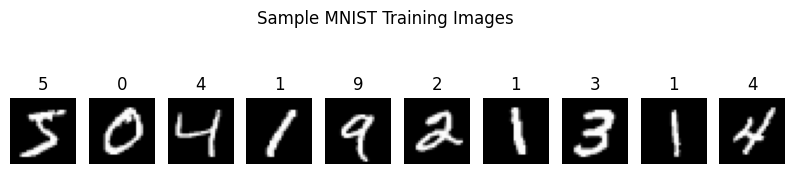

In [3]:
# Sample images from the dataset
plt.figure(figsize=(10, 2.5))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.suptitle('Sample MNIST Training Images')
plt.savefig("output/Exp8_sample_digits.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# Step 3: Normalize data
X_train = X_train / 255.0
X_test = X_test / 255.0

# Step 4: One-hot encode labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
print("Pixel range after normalization:", X_train.min(), "to", X_train.max())
print("Label shape after one-hot encoding:", y_train.shape)

Pixel range after normalization: 0.0 to 1.0
Label shape after one-hot encoding: (60000, 10)


In [5]:
# Step 5: Build ANN model
model = Sequential()
model.add(Flatten(input_shape=(28, 28)))          # Flatten 28x28 to 784
model.add(Dense(128, activation='relu'))          # Hidden layer
model.add(Dense(10, activation='softmax'))        # Output layer for 10 classes
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 flatten (Flatten)           (None, 784)               0         


 dense (Dense)               (None, 128)               100480    


 dense_1 (Dense)             (None, 10)                1290      


Total params: 101770 (397.54 KB)


Trainable params: 101770 (397.54 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [6]:
# Step 6: Compile and train the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.1, verbose=2)

Epoch 1/5


1688/1688 - 3s - loss: 0.2731 - accuracy: 0.9214 - val_loss: 0.1233 - val_accuracy: 0.9633 - 3s/epoch - 2ms/step


Epoch 2/5


1688/1688 - 2s - loss: 0.1229 - accuracy: 0.9645 - val_loss: 0.0972 - val_accuracy: 0.9708 - 2s/epoch - 1ms/step


Epoch 3/5


1688/1688 - 2s - loss: 0.0837 - accuracy: 0.9754 - val_loss: 0.0837 - val_accuracy: 0.9772 - 2s/epoch - 1ms/step


Epoch 4/5


1688/1688 - 2s - loss: 0.0645 - accuracy: 0.9799 - val_loss: 0.0855 - val_accuracy: 0.9763 - 2s/epoch - 1ms/step


Epoch 5/5


1688/1688 - 2s - loss: 0.0487 - accuracy: 0.9856 - val_loss: 0.0769 - val_accuracy: 0.9777 - 2s/epoch - 1ms/step


In [7]:
# Step 7: Evaluate on test set
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

Test Loss: 0.0705
Test Accuracy: 0.9799


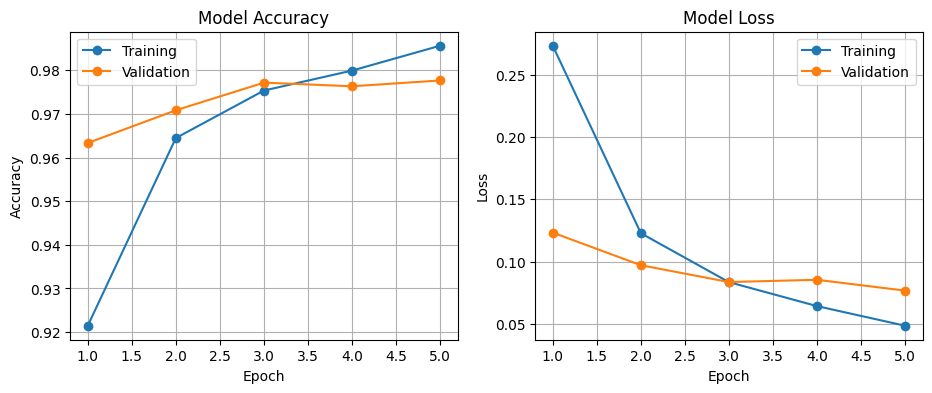

In [8]:
# Training history
epochs = range(1, len(history.history['accuracy']) + 1)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], marker='o', label='Training')
plt.plot(epochs, history.history['val_accuracy'], marker='o', label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Model Accuracy'); plt.legend(); plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], marker='o', label='Training')
plt.plot(epochs, history.history['val_loss'], marker='o', label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Model Loss'); plt.legend(); plt.grid(True)
plt.savefig("output/Exp8_training_history.png", dpi=150, bbox_inches="tight")
plt.show()

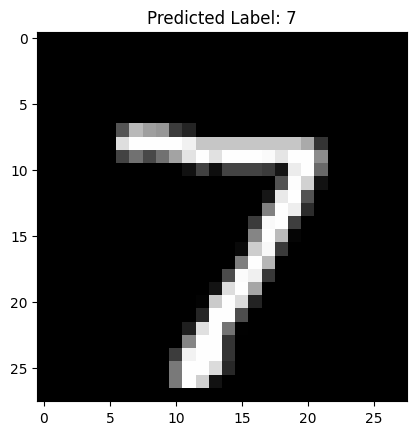

In [9]:
# Step 8: Predict and visualize
predictions = model.predict(X_test, verbose=0)
plt.imshow(X_test[0], cmap='gray')
plt.title(f'Predicted Label: {np.argmax(predictions[0])}')
plt.savefig("output/Exp8_first_prediction.png", dpi=150, bbox_inches="tight")
plt.show()

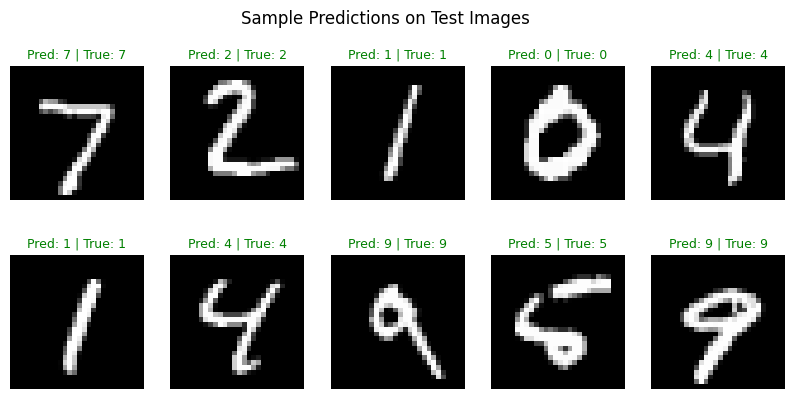

Misclassified test images: 201 out of 10000


In [10]:
# More sample predictions (green = correct, red = wrong)
pred_labels = np.argmax(predictions, axis=1)
true_labels = np.argmax(y_test, axis=1)

plt.figure(figsize=(10, 4.5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    color = 'green' if pred_labels[i] == true_labels[i] else 'red'
    plt.title(f'Pred: {pred_labels[i]} | True: {true_labels[i]}', color=color, fontsize=9)
    plt.axis('off')
plt.suptitle('Sample Predictions on Test Images')
plt.savefig("output/Exp8_sample_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Misclassified test images:", (pred_labels != true_labels).sum(), "out of", len(true_labels))

## Conclusion
A feedforward Artificial Neural Network (Flatten -> Dense 128 ReLU -> Dense 10 Softmax) was trained for 5 epochs on MNIST and evaluated on the 10,000 test images. Sample test images were visualized with their predicted labels.